# Spread locator : A statistical distribution analysis model

In [31]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from scipy import stats

In [32]:
Data = pd.read_csv("spread_locator_dataset.csv")
Data

,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
0,e98aa092-3770-4fdb-9502-5b5a6a244811,CUST2824,3821.34,2023-01-26,3,North,Fail
1,11ba6918-dba0-41e5-96cf-f5a7b95f0103,CUST1409,2781.84,2023-01-28,0,East,Fail
2,82b7654b-6eb7-4579-89a0-1a9edec0a7bb,CUST5506,4120.97,2023-01-28,0,South,Fail
3,f7166574-f400-4d53-b526-0b11f6619ddf,CUST5012,6383.78,2023-01-18,2,South,Success
4,8632fe26-b507-4068-9c68-1b2fa04fecb3,CUST4657,2651.61,2023-01-04,4,North,Success
...,...,...,...,...,...,...,...
215,10c2a8f2-89d0-485c-bf8f-9508d32a02fc,CUST5563,4356.76,2023-01-12,2,South,Fail
216,5618814b-f7e2-424d-9617-9fc8d8643370,CUST8579,2025.53,2023-01-29,6,South,Fail
217,5636c9e7-9d54-4654-9c89-fdf31be87d96,CUST5092,2648.08,2023-01-30,1,West,Fail
218,6ba09450-a455-4983-bbad-3dad292cc839,CUST2235,2338.62,2023-01-26,3,North,Success


In [33]:
Data.shape

(220, 7)

In [34]:
Data.head()

,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
0,e98aa092-3770-4fdb-9502-5b5a6a244811,CUST2824,3821.34,2023-01-26,3,North,Fail
1,11ba6918-dba0-41e5-96cf-f5a7b95f0103,CUST1409,2781.84,2023-01-28,0,East,Fail
2,82b7654b-6eb7-4579-89a0-1a9edec0a7bb,CUST5506,4120.97,2023-01-28,0,South,Fail
3,f7166574-f400-4d53-b526-0b11f6619ddf,CUST5012,6383.78,2023-01-18,2,South,Success
4,8632fe26-b507-4068-9c68-1b2fa04fecb3,CUST4657,2651.61,2023-01-04,4,North,Success


In [35]:
Data.tail()

,transaction_id,customer_id,transaction_amount,transaction_date,transaction_count,region,transaction_status
215,10c2a8f2-89d0-485c-bf8f-9508d32a02fc,CUST5563,4356.76,2023-01-12,2,South,Fail
216,5618814b-f7e2-424d-9617-9fc8d8643370,CUST8579,2025.53,2023-01-29,6,South,Fail
217,5636c9e7-9d54-4654-9c89-fdf31be87d96,CUST5092,2648.08,2023-01-30,1,West,Fail
218,6ba09450-a455-4983-bbad-3dad292cc839,CUST2235,2338.62,2023-01-26,3,North,Success
219,c7d958bb-62b5-43a8-bfb9-30edc213fa85,CUST8260,3105.52,2023-01-28,1,South,Fail


## Part-A : Theoretical Foundation

###  (1) What is statistical distribution?

A statistical distribution describes how values of a variable are spread or distributed across for possible outcomes.

It shows:
- Possible values
- Probability of each value

Two main types:

1. **Discrete Distribution** (e.g., Binomial , Bernoulli , poisson)
2. **Continuous Distribution** (e.g., Normal , Exponential , Uniform)

### (2): What is Q-Q plot and why is it used? 

A Q-Q(Quantile-Quantile) plot is a graphical tool to check if a dataset follows a theoretical distribution (usually Normal.)

why is it used : 

- Many statistical models assume normality; this is how we verify that assumption.

### (3) Difference between Discrete and Continuous Distributions.

**Discrete** distribution
- Discrete distribution means countable outcomes (finite or step-wise).
- Discrete distribution use PMF(Probability Mass Funtion).

**Continuous** distribution
- Continuous distribution means uncountable outcomes(Values within a continuous interval).
- Continuous distribution use PDF(Probability Density Function).

### (4) What is Bernoulli distribution?

**Bernoulli** distribution
- The simplest distribution describing a random experiment with exactly two outcomes : Success(1) or Failure(0).

### (5) What is binomial distribution?

**Binomial** distribution

- The binomial distribution models the number of successs(*k*) in **n** independent Bernoulli trials.  

### (6) Explain Log-Normal distribution.

- The lognormal distribution, sometimes called the Galton distribution, is a probability distribution whose logarithm has a normal distribution. The lognormal distribution is applicable when the quantity of interest must be positive, because log(x) exists only when x is positive.

**Common in**:
- Time-to-failure 
- Income
- duration data

### (7) Explain Power-Law distribution

- **A Power-Law distribution** is a statistical relationship where the frequency of an event varies as a power of its magnitude.

Where to use:
- α > 1 is the power-law exponent
- Larger α → faster decay
- Heavy tail distribution

### (8) What is Box-cox transform?

The Box–Cox transformation is a method used to:

-	Make data more normally distributed
-	Stabilize variance
-	Improve performance of regression models
-	Reduce skewness

Works only for **positive values (X > 0)**

### (9) Explain poisson distribution with an example.

- When we stop measuring continuous variables and start counting a fixed interval , we need the Poisson distirbution.

**Example**:

- Number of emails received in an hour.
- Number of cars passing a toll booth per minute.
- Number of printing errors per 100 pages.

### (10) What is Z-score Probability?

- A Z-score tells us exactly how many standard deviations a data point is away from the mean.
- It is Used to convert normal variable to standard normal distribution.

**Formula** :
Z = (X - μ) / σ

It is Used to convert normal variable to standard normal distribution.

### (11) differentiate probability density function(pdf) and cumulative density function(cdf)

- The **Probability Density Function (PDF)** describes the relative likelihood of a continuous random variable falling within a specific range, whereas the **Cumulative Distribution Function (CDF)** provides the probability that the variable takes a value less than or equal to a specific point.

## Part-B : Data Anaysis & Testing Tasks: 

### Task-1 : Fit the Bernoulli and Binomial distributions(transaction occurence & weekly count)

#### Bernoulli distribution

In [36]:
from scipy.stats import bernoulli,binom

p = (Data['transaction_status'] == 'Success').mean()
print(f"Probability of Success (p) : {p:.4f}")
print(f"Probability of Failure (1-p): {1-p:.4f}")

x_success = 1
x_failure = 0

bern_success_scipy = bernoulli.pmf(1, p)
bern_failure_scipy = bernoulli.pmf(0, p)

print(f"\nBernoulli PMF (Success=1) : {bern_success_scipy:.4f}")
print(f"Bernoulli PMF (Failure=0) : {bern_failure_scipy:.4f}")

Probability of Success (p) : 0.4455
Probability of Failure (1-p): 0.5545

Bernoulli PMF (Success=1) : 0.4455
Bernoulli PMF (Failure=0) : 0.5545


#### Binomial distribution

In [37]:
p = (Data['transaction_status'] == 'Success').mean()
n = int(Data['transaction_count'].max())   
k = int(Data['transaction_count'].mode()[0])  

binomial_scipy = binom.pmf(k, n, p)
print(f"\nBinomial PMF (k={k}, n={n}, p={p:.4f}) : {binomial_scipy:.4f}")


Binomial PMF (k=2, n=9, p=0.4455) : 0.1152


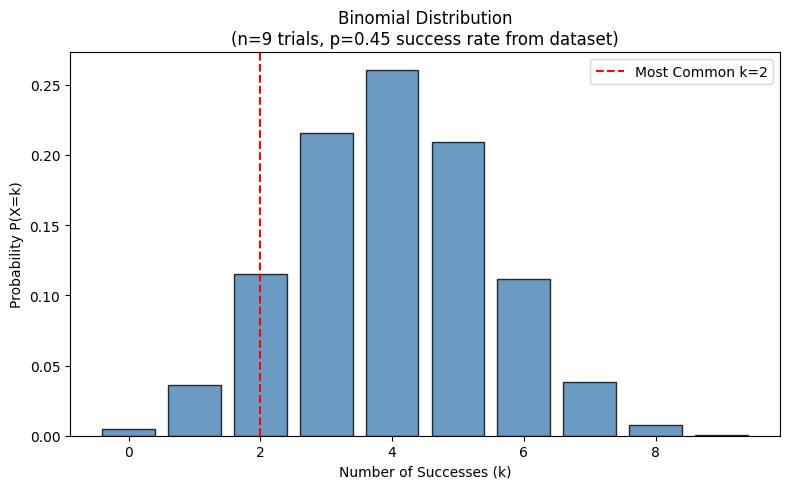

In [38]:
k_values = np.arange(0, n + 1)
pmf_values = binom.pmf(k_values, n, p)

plt.figure(figsize=(8, 5))
plt.bar(k_values, pmf_values, color='steelblue', edgecolor='black', alpha=0.8)
plt.axvline(k, color='red', linestyle='--', label=f'Most Common k={k}')
plt.title(f'Binomial Distribution\n(n={n} trials, p={p:.2f} success rate from dataset)')
plt.xlabel('Number of Successes (k)')
plt.ylabel('Probability P(X=k)')
plt.legend()
plt.tight_layout()
plt.show()

### Task-2 : Fit the data to poisson distribution

In [39]:
from scipy.stats import poisson

Data['transaction_date'] = pd.to_datetime(Data['transaction_date'])
transactions_per_day = Data.groupby('transaction_date').size()

lam = round(transactions_per_day.mean())  
k   = int(transactions_per_day.mode()[0]) 

poisson_scipy = poisson.pmf(k, lam)

print(f"\nPoisson PMF P(X={k}) : {poisson_scipy:.4f}")
print(f"Probability of exactly {k} transactions in a day = {poisson_scipy*100:.2f}%")


Poisson PMF P(X=6) : 0.1490
Probability of exactly 6 transactions in a day = 14.90%


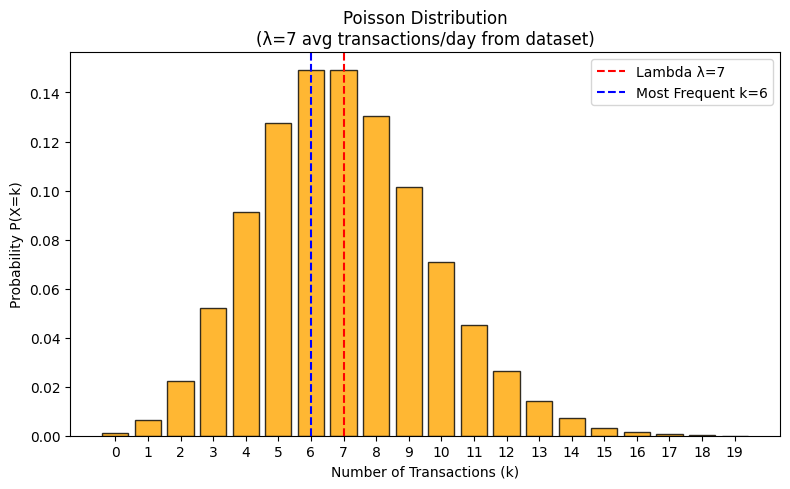

In [40]:
k_values  = np.arange(0, 20)
pmf_values = poisson.pmf(k_values, lam)

plt.figure(figsize=(8, 5))
plt.bar(k_values, pmf_values, color='orange', edgecolor='black', alpha=0.8)
plt.axvline(lam, color='red',  linestyle='--', label=f'Lambda λ={lam}')
plt.axvline(k,   color='blue', linestyle='--', label=f'Most Frequent k={k}')
plt.title(f'Poisson Distribution\n(λ={lam} avg transactions/day from dataset)')
plt.xlabel('Number of Transactions (k)')
plt.ylabel('Probability P(X=k)')
plt.xticks(k_values)
plt.legend()
plt.tight_layout()
plt.show()

### Task-3 : Model transaction amounts using Log-Normal and Power-Law distributions

In [41]:
amount = Data['transaction_amount'].dropna()

mean  = np.mean(np.log(amount))   
sigma = np.std(np.log(amount))   

print(f"Mean  (log scale) : {mean:.4f}")
print(f"Sigma (log scale) : {sigma:.4f}")

Mean  (log scale) : 8.0007
Sigma (log scale) : 0.4749


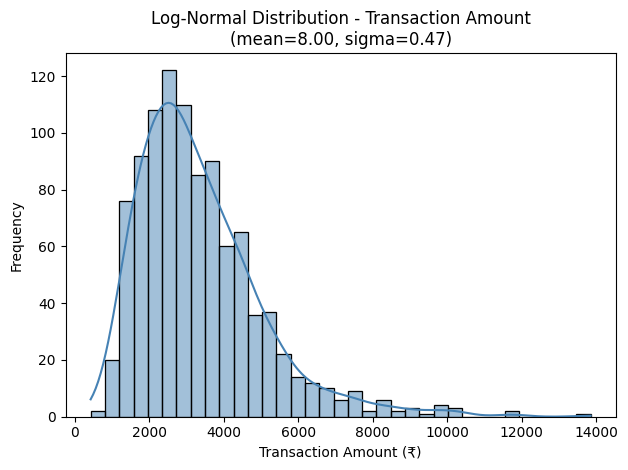

In [42]:
lognormal_data = np.random.lognormal(mean=mean, sigma=sigma, size=1000)

sns.histplot(lognormal_data, kde=True, color='steelblue')
plt.title(f"Log-Normal Distribution - Transaction Amount\n(mean={mean:.2f}, sigma={sigma:.2f})")
plt.xlabel("Transaction Amount (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Task-4 : Generate & Interprete Q-Q plot to test nomality

In [43]:
stat, p_value = stats.shapiro(amount.sample(50, random_state=42))

print(f"Shapiro-Wilk Test Stat : {stat:.4f}")
print(f"P-Value : {p_value:.4f}")

if p_value > 0.05:
    print("\n Data is NORMAL (points follow the red line)")
else:
    print("\n Data is NOT Normal (points deviate from red line)")

Shapiro-Wilk Test Stat : 0.6147
P-Value : 0.0000

 Data is NOT Normal (points deviate from red line)


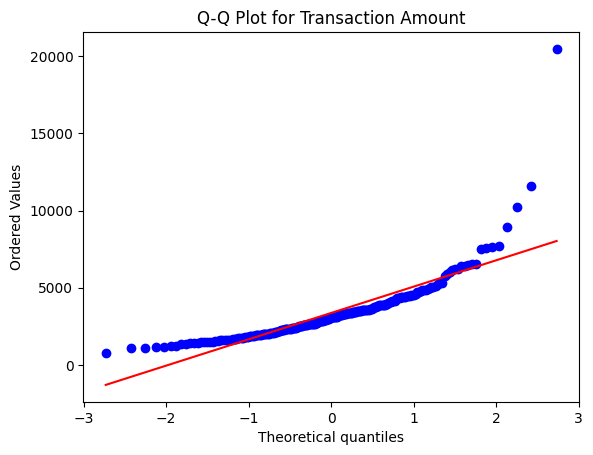

In [44]:
stats.probplot(amount, dist="norm", plot=plt)
plt.title("Q-Q Plot for Transaction Amount")
plt.show()

### Task-5 : Applly Box-cox transform to stabilize variance.

In [45]:
from scipy.stats import boxcox

amount = Data['transaction_amount'].dropna()
amount = amount[amount > 0]

amount_boxcox, lambda_value = boxcox(amount)

print(f"Transformed Data : {amount_boxcox}")
print(f"Lambda Value (λ) : {lambda_value:.4f}")

Transformed Data : [4.28561065 4.21207995 4.30248114 4.39588421 4.20060422 4.20060603
 4.40163039 4.31569915 4.17201743 4.29075812 4.17276091 4.17247735
 4.2566165  3.98265743 4.0087859  4.1605733  4.10363855 4.26491158
 4.11709048 4.05118005 4.38998493 4.20161074 4.23637507 4.0495163
 4.16278872 4.24144048 4.08570969 4.27192094 4.1558168  4.19367021
 4.15568394 4.42914677 4.22686335 4.09783959 4.32173469 4.07655858
 4.25280009 3.9761533  4.06238474 4.2514133  4.31251487 4.24846297
 4.21477242 4.19253313 4.04230042 4.140927   4.17310109 4.34709034
 4.26826637 4.00353317 4.26603631 4.18233894 4.1463072  4.29847781
 4.3442934  4.3335551  4.12585379 4.19155182 4.26685612 4.33833365
 4.17082544 4.20642021 4.0915284  4.07979297 4.32063988 4.3786524
 4.21995117 4.34134533 4.27032053 4.15028001 4.27029311 4.39742192
 4.22423016 4.40014291 3.88059589 4.32166472 4.23865531 4.19278668
 4.23920577 3.97222905 4.20234373 4.2698052  4.39124647 4.16601275
 4.12974853 4.16804739 4.33183589 4.26656959 

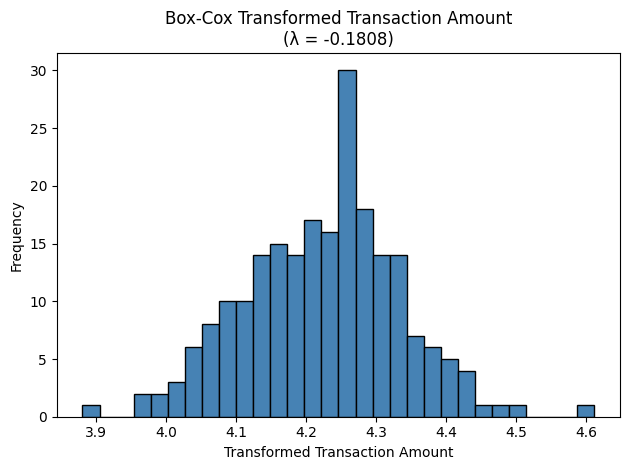

In [46]:
plt.hist(amount_boxcox, bins=30, color='steelblue', edgecolor='black')
plt.title(f"Box-Cox Transformed Transaction Amount\n(λ = {lambda_value:.4f})")
plt.xlabel("Transformed Transaction Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Task-6 : Calculate Z-Scores for transaction amount and compute probability of transactions exceeding Rs,5,000

In [47]:
from scipy.stats import norm

amount  = Data['transaction_amount'].dropna()
mean    = amount.mean()
std     = amount.std()
x_value = 5000  

z_score    = (x_value - mean) / std
prob_above = 1 - norm.cdf(z_score)

print(f"Mean : ₹{mean:.2f}")
print(f"Std Dev : ₹{std:.2f}")
print(f"X Value : ₹{x_value}")
print(f"Z-Score : {z_score:.4f}")
print(f"Probability above ₹{x_value} : {prob_above:.4f} ({prob_above*100:.2f}%)")

Mean : ₹3365.19
Std Dev : ₹1985.71
X Value : ₹5000
Z-Score : 0.8233
Probability above ₹5000 : 0.2052 (20.52%)


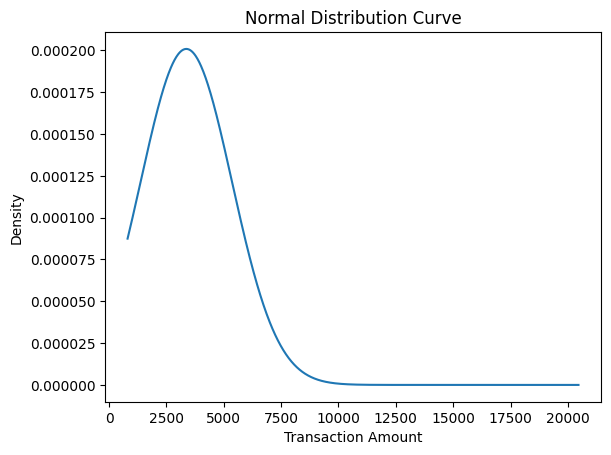

In [48]:
x_vals = np.linspace(amount.min(), amount.max(), 1000)
pdf_vals = norm.pdf(x_vals, mean, std)

plt.plot(x_vals, pdf_vals)
plt.title("Normal Distribution Curve")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.show()

### Task-7 : Plot and interpret PDF and CDF for transaction amounts

#### PDF(Probability Density Funtion)

In [49]:
pdf_value = norm.pdf(5000, mean, std)
pdf_value


np.float64(0.00014315685178291042)

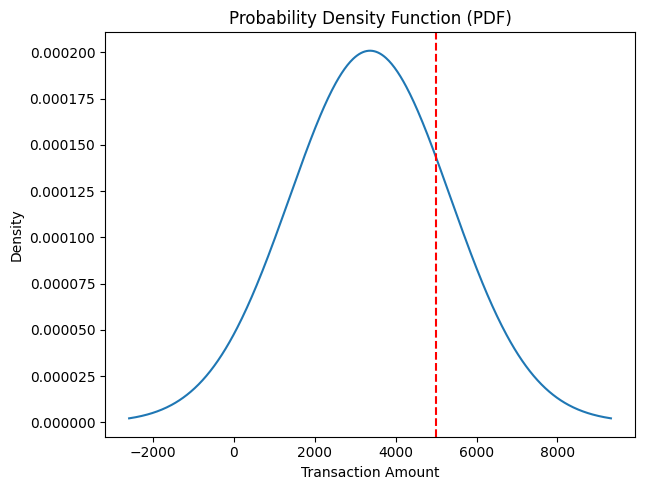

In [50]:
mu    = amount.mean()
sigma = amount.std()
x     = 5000

x_values   = np.linspace(mu - 3*sigma, mu + 3*sigma, 500)
pdf_values = norm.pdf(x_values, mu, sigma)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(x_values, pdf_values)
plt.axvline(x, color="red", linestyle="--")
plt.title("Probability Density Function (PDF)")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

#### CDF(Cumulitive Density Fumtion)

In [51]:
cdf_value = norm.cdf(5000, mean, std)
cdf_value

np.float64(0.7948279043244562)

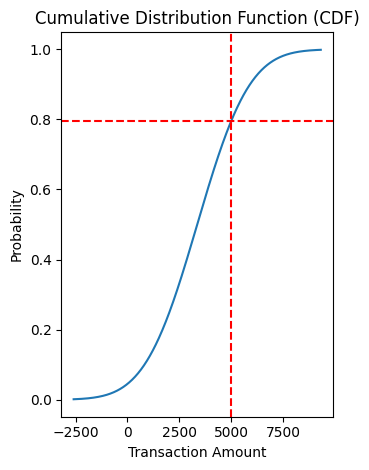

In [52]:
mu    = amount.mean()
sigma = amount.std()
x     = 5000

x_values   = np.linspace(mu - 3*sigma, mu + 3*sigma, 500)
cdf_values = norm.cdf(x_values, mu, sigma)

plt.subplot(1, 2, 2)
plt.plot(x_values, cdf_values)
plt.axvline(x, color="red", linestyle="--")
plt.axhline(cdf_value, color="red", linestyle="--")
plt.title("Cumulative Distribution Function (CDF)")
plt.xlabel("Transaction Amount")
plt.ylabel("Probability")
plt.tight_layout()
plt.show()

### Task-8 : Conclude which distribution best fits for the datasset and justify insights for decison-making

In [53]:
from scipy.stats import kstest, lognorm

mu, sigma = norm.fit(amount)
ks_norm, p_norm  = kstest(amount, 'norm', args=(mu, sigma))

shape, loc, scale = lognorm.fit(amount, floc=0)
ks_log, p_log = kstest(amount, 'lognorm', args=(shape, loc, scale))

lam = amount.mean()
ks_pois, p_pois = kstest(amount, 'poisson', args=(lam,))

print(f"{'Distribution':<15} {'KS Stat':<12} {'P-Value'}")
print()
print(f"{'Normal':<15} {ks_norm:<12.4f} {p_norm:.4f}")
print(f"{'Log-Normal':<15} {ks_log:<12.4f} {p_log:.4f}")
print(f"{'Poisson':<15} {ks_pois:<12.4f} {p_pois:.4f}")
print()

results = {'Normal': ks_norm, 'Log-Normal': ks_log, 'Poisson': ks_pois}
best    = min(results, key=results.get)
print(f"Best Fit Distribution : {best}")

Distribution    KS Stat      P-Value

Normal          0.1404       0.0003
Log-Normal      0.0378       0.8999
Poisson         0.5363       0.0000

Best Fit Distribution : Log-Normal
